# Cyclone sensor data — Task 1

Three and a half years of 5-minute readings from six cyclone tags (2017-01-01 → 2020-08-07). The notebook goes in the order of the brief: cleaning → shutdowns → operating states → anomalies and root causes → 1-hour forecast → insights.

The heavy lifting lives in the small `cyclone/` package next to this notebook. Each module's docstring explains the method choices, and the notebook carries the reasoning tied to what the data showed.

**Run:** from the repo root, `uv sync`, put `data.xlsx` in `given/`, then *Restart & Run All*. It takes about 3 minutes on a laptop; the first run also caches the xlsx as parquet.

In [1]:
import os
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cyclone import anomalies as an, forecasting as fcm, plots, shutdowns as sd, states as st
from cyclone.data import SENSORS, SHORT, clean, load_raw

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

# Raw export: bundled at Task1/data/data.xlsx; set CYCLONE_DATA=/path/to/data.xlsx to use another copy
DATA = Path(os.environ.get("CYCLONE_DATA", "data/data.xlsx"))
OUT, PLOTS, CACHE = Path("."), Path("plots"), Path("cache")
SUPPORT = Path("outputs") / "supporting"  # the four required CSVs sit in Task1/ as the brief lists them; extra detail here
SUPPORT.mkdir(parents=True, exist_ok=True)
# plots are grouped by section of the brief
for sub in ["1_eda", "2_shutdowns", "3_states", "4_anomalies", "5_forecast"]:
    (PLOTS / sub).mkdir(parents=True, exist_ok=True)
if not (CACHE / "raw.parquet").exists() and not DATA.exists():
    raise FileNotFoundError(f"Raw data not found: expected {DATA.resolve()} (or set CYCLONE_DATA=/path/to/data.xlsx)")

## 1. Data preparation

The export mixes numbers with PI-historian status strings (`I/O Timeout`, `Not Connect`, `Unit Down`, …) whenever a tag couldn't be read, so every column loads as text. Cleaning is deliberately limited to values that **cannot be real**:

| issue | rule | why |
|---|---|---|
| status strings | → missing | sensor/communication faults, not measurements |
| 1375.0 repeated exactly on two temperature tags | → missing | transmitter range cap |
| material temp of −185 °C, cone draft of +489 Pa | → missing | physically impossible in this process |
| a temperature tag near ambient (< 100 °C) while the other two read > 500 °C | → missing | signal dropout: heat can't vanish at one point of the gas path |
| any tag frozen at one value for ≥ 20 min while hot | → missing | stale or substituted value (e.g. inlet temp at exactly 800.0 for 25 min); real 0.01-resolution readings never sit still |
| 861 missing timestamps (three whole days + scattered) | reindexed to a strict 5-min grid | required by the brief, and lets gaps be seen |
| gaps ≤ 30 min | time interpolation | short enough that interpolation is honest |
| gaps > 30 min | left missing | interpolating across hours would invent process behaviour |

Statistical outliers are **not** clipped. They are what section 4 is looking for.

In [2]:
raw = load_raw(DATA, CACHE)
df, quality = clean(raw)
quality.to_csv(SUPPORT / "data_quality.csv", index=False)
print(f"{len(raw):,} rows in export -> {len(df):,} on the 5-min grid; "
      f"{df[SENSORS].isna().any(axis=1).sum():,} rows still have a missing tag "
      f"({df[SENSORS].isna().any(axis=1).mean():.1%})")
quality.set_index("sensor")

377,719 rows in export -> 378,580 on the 5-min grid; 5,858 rows still have a missing tag (1.5%)


,Comm Fail,Configure,I/O Timeout,Not Connect,Scan Timeout,Unit Down,physically_invalid,dropout_ambient,stale_value,missing_timestamps,interpolated,still_missing
sensor,,,,,,,,,,,,
Cyclone_Inlet_Gas_Temp,2,108,470,723,17,0,0,34,913,861,115,2984
Cyclone_Gas_Outlet_Temp,2,108,470,723,17,1,28,1,904,861,122,2975
Cyclone_Material_Temp,2,108,470,723,17,271,86,1146,3063,861,725,5086
Cyclone_Inlet_Draft,2,108,470,723,17,2,0,0,748,861,109,2822
Cyclone_cone_draft,2,108,470,723,17,0,4,0,1309,861,334,3160
Cyclone_Outlet_Gas_draft,2,108,470,723,17,1,0,0,748,861,103,2827


`Cyclone_Material_Temp` is clearly the weakest instrument. It has nearly all the `Unit Down` codes, ~1,150 near-ambient dropouts while the gas is hot, and 2–4× the stale samples of any other tag. That feeds into the recommendations at the end.

In [3]:
df[SENSORS].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).T.round(1)

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Cyclone_Inlet_Gas_Temp,375596.0,727.0,328.9,14.4,23.5,30.2,856.3,882.4,901.1,934.1,969.9,1157.6
Cyclone_Gas_Outlet_Temp,375605.0,715.3,325.6,13.8,23.8,30.2,801.5,871.5,899.3,933.0,961.6,1351.4
Cyclone_Material_Temp,373494.0,752.4,349.7,0.0,0.0,20.8,868.3,913.6,943.8,986.0,1018.2,1369.0
Cyclone_Inlet_Draft,375758.0,-141.2,77.7,-396.4,-236.8,-221.1,-193.5,-169.4,-136.1,0.9,13.8,41.6
Cyclone_cone_draft,375420.0,-164.5,90.2,-459.3,-278.2,-258.8,-226.8,-198.6,-143.6,0.3,1.8,41.2
Cyclone_Outlet_Gas_draft,375753.0,-177.7,99.2,-456.7,-296.6,-277.6,-247.2,-215.2,-169.9,4.7,13.4,40.3


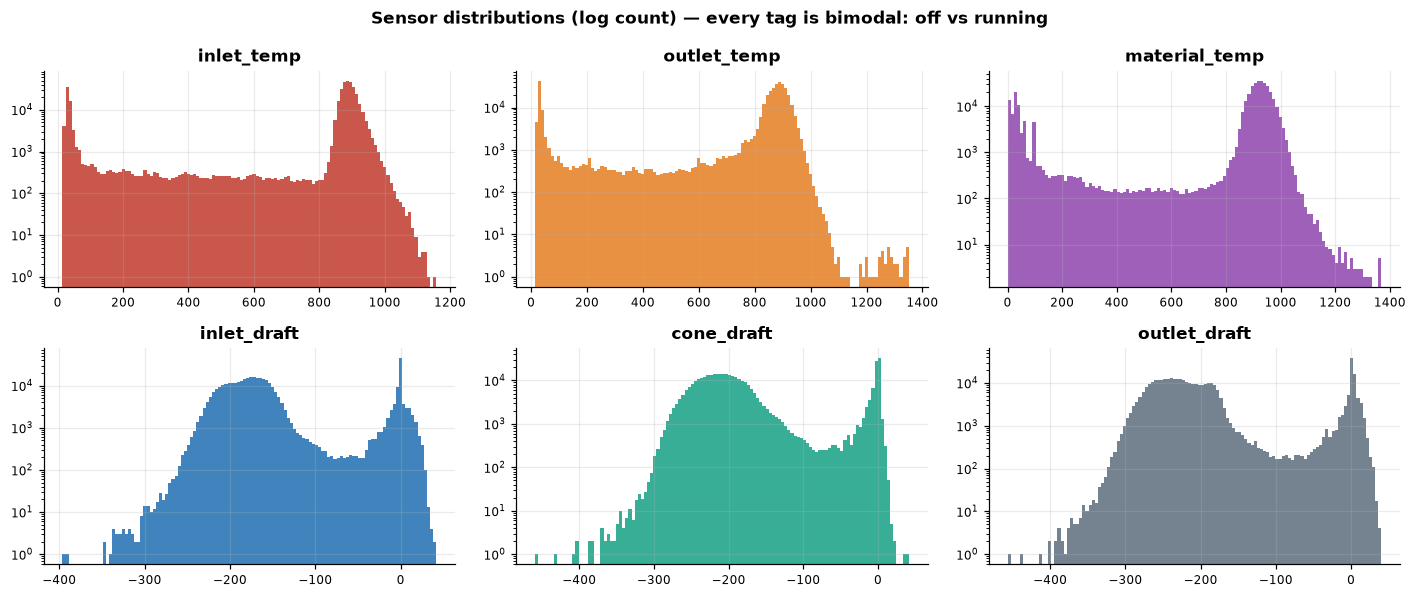

In [4]:
plots.distributions(df, PLOTS / "1_eda" / "01_distributions.png");

Every tag is bimodal: one mode for "off" (temperatures near ambient, drafts near 0 Pa) and one for "running". This matters for the correlation matrix. Computed over all rows, it mostly measures the on/off switching, so it is shown for running time as well.

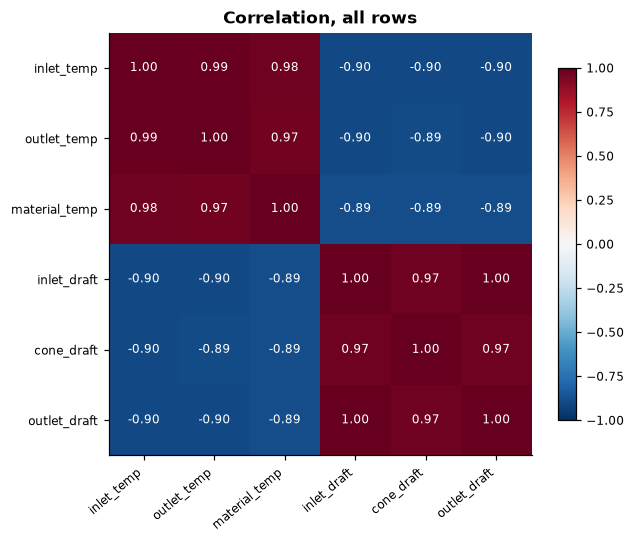

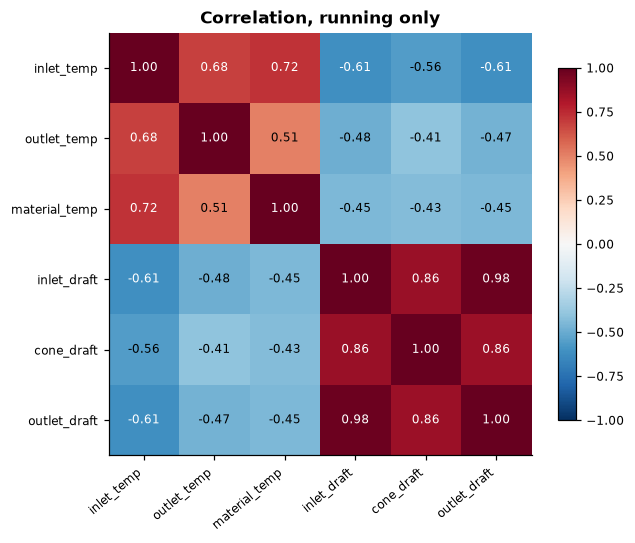

In [5]:
running_rough = df["Cyclone_Inlet_Gas_Temp"] > 500
c_all = df[SENSORS].corr()
c_run = df.loc[running_rough, SENSORS].corr()
plots.correlation(c_all, "Correlation, all rows", PLOTS / "1_eda" / "02_corr_all.png")
plots.correlation(c_run, "Correlation, running only", PLOTS / "1_eda" / "02_corr_running.png");

Over all rows, inlet vs outlet gas temperature has r = 0.99 and the temperatures vs drafts about −0.9. Restricted to running time, these drop to roughly 0.65 and −0.55. The three drafts remain tightly coupled (0.85–0.98), as expected for one gas path pulled by one fan. In other words, the tags are far less redundant while the plant is running than the headline matrix suggests.

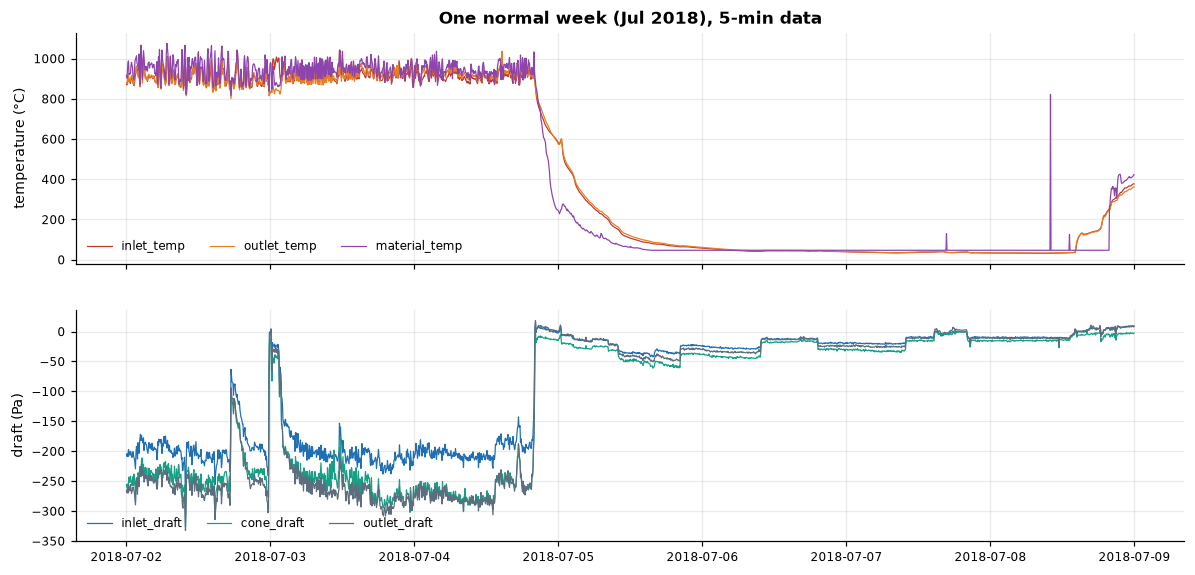

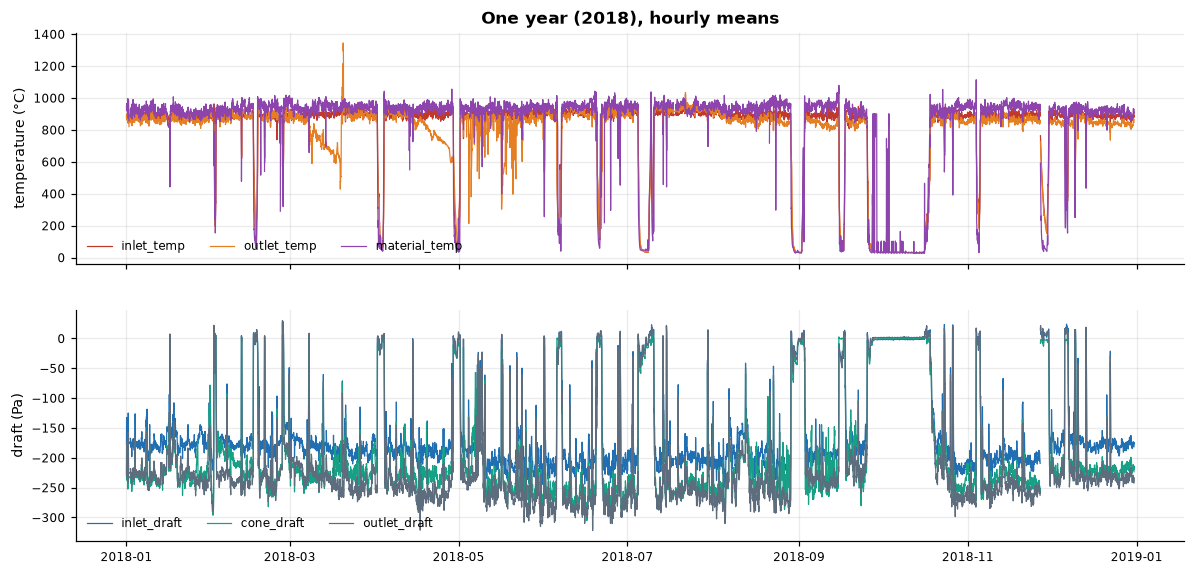

In [6]:
plots.temps_and_drafts(df, "2018-07-02", "2018-07-08 23:55", "One normal week (Jul 2018), 5-min data",
                       path=PLOTS / "1_eda" / "03_week.png")
plots.temps_and_drafts(df, "2018-01-01", "2018-12-31 23:55", "One year (2018), hourly means",
                       resample="1h", path=PLOTS / "1_eda" / "03_year.png");

In a normal week, inlet gas sits around 850–950 °C with ±30 °C wiggle, and the drafts hold steady between −150 and −250 Pa. Over the year, the obvious structure is the stops. Long ones run for weeks (Sep–Oct), and short dips to zero are trips.

## 2. Shutdown / idle detection

Because inlet gas temperature is so cleanly bimodal, a threshold is the right model here, and anything fancier would only add parameters. The threshold is **not hand-picked**: it is the Otsu split of the histogram (the value that best separates the two modes).

Three rules turn the threshold into events:
- **hysteresis:** off below *T*, back on only above *T* + 100 °C, so a slow ramp crossing *T* doesn't flicker;
- **merge:** stops separated by a restart shorter than 1 h are one stop;
- **minimum length:** events shorter than 30 min are dropped.

Drafts collapsing to ~0 Pa during these periods (fan off) independently confirm the split. The ID fan stopping while the line stays **hot** is a different event. It is handled in the fan-off layer below and is not counted as a shutdown.

In [7]:
shut, off, T_OFF = sd.detect(df)
print(f"Otsu threshold: {T_OFF:.0f} °C")
print("draft while 'off':", df.loc[off, "Cyclone_Inlet_Draft"].median().round(1),
      "Pa   while running:", df.loc[~off, "Cyclone_Inlet_Draft"].median().round(1), "Pa")
shut.to_csv(OUT / "shutdown_periods.csv", index=False)
sd.summary(shut, df.index)

Otsu threshold: 477 °C
draft while 'off': -1.4 Pa   while running: -178.1 Pa


,year,events,downtime_h,downtime_pct,median_event_h,longest_event_h
0,2017,10,1389.7,15.9,39.6,711.3
1,2018,16,1132.2,12.9,28.7,539.9
2,2019,10,2796.7,31.9,203.2,998.6
3,2020,3,967.1,18.4,21.9,940.5
4,all,39,6285.6,19.9,36.8,998.6


In [8]:
sens = sd.sensitivity(df, T_OFF)
sens

,threshold_c,events,downtime_h
0,327,31,5945.1
1,377,34,6058.8
2,427,37,6186.0
3,477,39,6285.6
4,527,43,6394.6
5,577,47,6476.2


**Robustness:** moving the threshold by ±50 °C changes total downtime by under 2% and the event count by about ±3. The headline numbers don't depend on the exact cut.

### Fan-off periods: not shutdowns, not running

A shutdown above is the line going **cold**. The ID fan can also stop while the gas is still hot: all three drafts jump to ~0 Pa within one sample and the temperatures start to fall. No gas is being pulled through the cyclone then, so this is not running either. These periods are taken out of the running data before clustering (section 3) and classified by what surrounds them (`shutdowns.fan_off_periods`):
- **coast-down:** a shutdown follows within 3 h, so this is the first part of that stop, before the gas has cooled past the threshold;
- **start-up idle:** within 1 h after a restart, with the burner on and the fan not yet started;
- **fan trip:** anything else. The fan stopped mid-run and the line recovered. It is *transient* if the fan was back within 60 min, *extended* otherwise.

Fan trips are reported as **incidents** in `anomalous_periods.csv`, not as shutdowns: the line never went cold, and it was back at temperature within about an hour. The table after the next cell shows how the event count changes if they were counted as stops.

In [9]:
fan, fan_off = sd.fan_off_periods(df, off)
fan.to_csv(SUPPORT / "fan_off_periods.csv", index=False)
print(fan.groupby("kind").agg(periods=("period_id", "size"), median_min=("duration_min", "median"),
                              median_dip_c=("dip_c", "median")).to_string())
n_trip = int(fan["kind"].str.startswith("fan_trip").sum())
n_ext = int((fan["kind"] == "fan_trip_extended").sum())
pd.Series({
    "shutdowns (this definition: line goes cold)": len(shut),
    "if extended fan trips (fan off >= 60 min) also counted as stops": len(shut) + n_ext,
    "if every fan trip with draft ~0 Pa counted as a stop": len(shut) + n_trip,
}, name="events").to_frame().assign(vs_this_definition=lambda t: (t["events"] / len(shut)).round(1).astype(str) + "x")

                    periods  median_min  median_dip_c
kind                                                 
coast_down               39       415.0       -400.45
fan_trip_extended        66       132.5       -198.90
fan_trip_transient       91        25.0       -100.90
startup_idle             33       110.0         18.70


,events,vs_this_definition
shutdowns (this definition: line goes cold),39,1.0x
if extended fan trips (fan off >= 60 min) also counted as stops,105,2.7x
if every fan trip with draft ~0 Pa counted as a stop,196,5.0x


,event_id,start,end,duration_h,missing_pct
33,34,2019-09-14 11:15:00,2019-10-26 01:50:00,998.58,0.0
37,38,2020-03-23 03:40:00,2020-05-01 08:10:00,940.50,0.0
8,9,2017-09-19 08:45:00,2017-10-19 00:05:00,711.33,8.9
35,36,2019-11-29 18:40:00,2019-12-24 15:45:00,597.08,0.0
22,23,2018-09-25 21:05:00,2018-10-18 09:00:00,539.92,0.0
31,32,2019-06-03 10:20:00,2019-06-22 01:20:00,447.00,0.0


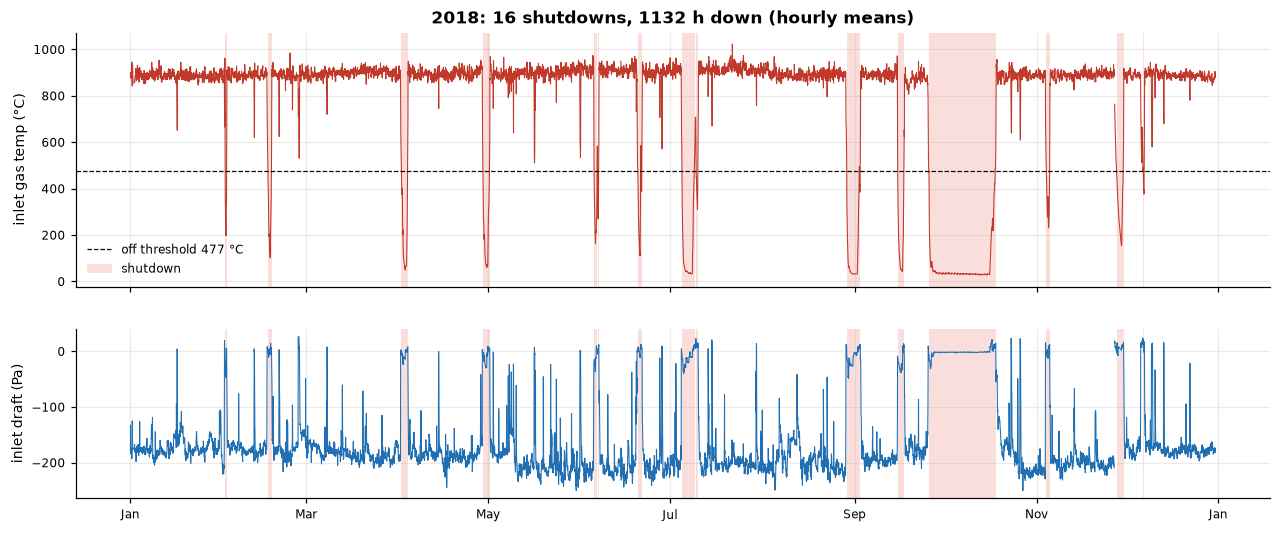

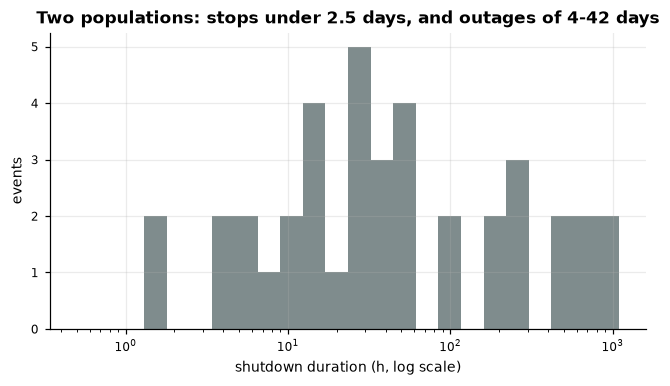

In [10]:
plots.shutdown_year(df, shut, 2018, T_OFF, PLOTS / "2_shutdowns" / "04_shutdowns_2018.png")
plots.duration_hist(shut, PLOTS / "2_shutdowns" / "04_shutdown_durations.png")
shut.sort_values("duration_h", ascending=False).head(6)

The durations form two separate groups with nothing in between: **26 stops shorter than 2.5 days** and **13 outages of 4–42 days**. The longest stop of each year 2017–2019 starts in the second half of **September** and lasts 3–6 weeks, which is consistent with an annual planned maintenance window. **23 Mar – 1 May 2020** lines up exactly with the national COVID-19 lockdown in India. 2019 is the worst year (32% downtime) because it had several long stops.

## 3. Operating states (running data only)

As the brief asks, idle time is excluded before clustering: shutdowns **and** the fan-off periods from section 2 (coast-downs, start-up idle and fan trips, 2.4% of non-shutdown time). What remains is the line hot with the ID fan pulling gas.

**Features.** The six raw tags are collinear, so on their own they mostly measure "how hot is the line". Added features capture what an operator would look at:
- `temp_drop` = inlet − outlet gas temperature (heat lost across the cyclone)
- `draft_dp` = inlet − outlet draft (pressure drop across the cyclone, which tracks gas flow and blockage)
- 1-h rolling std of inlet temperature and inlet draft (stability)
- 30-min change of inlet temperature and draft (ramping)

**Model.** Robust scaling → PCA (95% variance, 7 components) → KMeans. Then a 30-minute minimum-dwell filter makes each state an *episode* rather than per-sample flicker.

**Choosing k.**

In [11]:
feats = st.features(df)
active = st.active_mask(df, off, feats, fan_off)
Fa = feats[active]
print(f"running samples with complete features: {len(Fa):,} ({active.mean():.1%} of the grid); "
      f"fan-off samples excluded: {int(fan_off.sum()):,} ({fan_off.sum() / (~off).sum():.1%} of non-shutdown time)")

pre_k, _, _ = st.fit(Fa, 3)
k_table = st.choose_k(pre_k.transform(Fa))
k_table.round(3)

running samples with complete features: 290,768 (76.8% of the grid); fan-off samples excluded: 7,362 (2.4% of non-shutdown time)


,k,inertia,silhouette,davies_bouldin
0,3,2736234.404,0.451,1.062
1,4,2403139.645,0.174,1.488
2,5,2218600.367,0.164,1.509
3,6,2066144.329,0.165,1.544
4,7,1939739.743,0.167,1.458


Silhouette points to k = 3, but that is the textbook trap. At k = 3, one cluster holds 93% of running time and the other two are small outlying groups, which separate well and so inflate the score. The running data is one continuous cloud, not a set of blobs. HDBSCAN, run below as a cross-check, finds no density clusters at all and calls every sample noise.

So the task is to cut a continuum into **operationally meaningful bands**. k = 4 is the smallest k where each cluster has a distinct physical signature, shown in the table after naming. At k = 5 the load band splits into three bands that differ only by ~20 °C, with no new signature.

*Earlier version:* before fan-off time was excluded, k = 6 was needed, and two of those six clusters were the fan-off "trip cool-down" and "warm idle" periods. They are idle time, not operating states, so they now live in the fan-off layer instead. The four running states came back with the same medians to within ~1 °C and ~1 Pa.

In [12]:
from sklearn.cluster import HDBSCAN
Xs = pre_k.transform(Fa)
idx = np.random.default_rng(7).choice(len(Xs), 20_000, replace=False)
h = HDBSCAN(min_cluster_size=200).fit(Xs[idx])
print("HDBSCAN on a 20k sample:", h.labels_.max() + 1, "clusters, noise share", f"{(h.labels_ == -1).mean():.0%}")

HDBSCAN on a 20k sample: 0 clusters, noise share 100%


In [13]:
K = 4
pre, km, raw_labels = st.fit(Fa, K)
names = st.name_states(Fa, raw_labels)
labels = st.smooth(raw_labels)
print(f"smoothing relabelled {(labels != raw_labels).mean():.1%} of samples; "
      f"{len(st.episodes(raw_labels)):,} raw runs -> {len(st.episodes(labels)):,} episodes")

med = Fa.groupby(labels).median()[SENSORS + ["temp_drop", "draft_dp", "inlet_temp_std_1h", "inlet_draft_std_1h", "inlet_temp_delta_30m"]]
med.index = [names[i] for i in med.index]
med.rename(columns=SHORT).round(1)

smoothing relabelled 12.4% of samples; 54,097 raw runs -> 4,891 episodes


,inlet_temp,outlet_temp,material_temp,inlet_draft,cone_draft,outlet_draft,temp_drop,draft_dp,inlet_temp_std_1h,inlet_draft_std_1h,inlet_temp_delta_30m
High load,900.4,901.0,936.7,-200.7,-230.1,-254.9,-0.5,54.1,16.5,6.0,1.2
Normal load,880.9,873.7,915.5,-164.6,-197.0,-205.0,7.2,40.8,13.2,4.4,-1.0
Degraded: high outlet ΔT,895.2,756.4,939.6,-185.4,-221.0,-241.4,142.0,53.1,16.6,5.5,0.1
Unstable draft,897.9,872.3,922.3,-135.5,-162.9,-168.6,26.3,33.6,46.5,29.3,9.0


How the names follow from the medians (the rules are in `states.name_states`):

| state | signature | reading |
|---|---|---|
| **High load** | hottest (~900 °C), strongest draft (~−200 Pa) | full-rate running |
| **Normal load** | ~880 °C, ~−165 Pa | the bulk of running time |
| **Unstable draft** | normal temperatures, but draft std ~5× normal and weaker draft (~−135 Pa) | process upsets, oscillating fan or damper control |
| **Degraded: high outlet ΔT** | outlet gas reads ~140 °C below inlet, everything else normal | see the drift plot below: an instrument problem, not a process state |

In [14]:
summary = st.profile(df, Fa, labels, names)
summary.to_csv(OUT / "clusters_summary.csv", index=False)
ep = st.episodes(labels).assign(state=lambda e: e["state"].map(names),
                               duration_h=lambda e: (e["steps"] * 5 / 60).round(2))
ep[["state", "start", "end", "duration_h"]].to_csv(SUPPORT / "state_episodes.csv", index=False)
summary[["state", "share_of_running_pct", "episodes", "episodes_per_running_month",
         "median_episode_h", "p90_episode_h", "max_episode_h"]]

,state,share_of_running_pct,episodes,episodes_per_running_month,median_episode_h,p90_episode_h,max_episode_h
0,High load,43.8,2107,63.48,1.58,10.08,345.08
1,Normal load,49.6,2182,65.74,1.67,13.16,174.83
2,Degraded: high outlet ΔT,4.1,119,3.59,2.33,17.43,139.42
3,Unstable draft,2.4,483,14.55,1.08,1.83,4.00


**Are the states stable over time? Absolute vs baseline-relative features.** Absolute levels mix slow sensor drift and calendar periods into the states (the thermocouple drift below is one example). As a check, each tag minus its trailing 7-day running median (causal, past data only) is added next to the absolute features, and the stability of both versions is compared:
- *bootstrap ARI:* refit on resamples and compare the labels;
- *temporal ARI:* fit on 2017–2018, label 2019–2020;
- *monthly mix change:* the average month-to-month shift in the state mix.

In [15]:
rel = st.baseline_relative(df, active)
both = pd.concat([feats, rel], axis=1)[active].dropna()
stab = pd.DataFrame({"absolute features (used)": st.stability(Fa.loc[both.index], K),
                     "absolute + 7-day baseline-relative": st.stability(both, K)}).T
stab

,bootstrap_ari_mean,bootstrap_ari_min,temporal_ari,monthly_mix_change
absolute features (used),0.980,0.97,0.749,0.182
absolute + 7-day baseline-relative,0.972,0.96,0.732,0.152


**Result: keep the absolute features.** Both versions give the same four states. Adding the baseline-relative features makes the monthly mix ~16% smoother (0.152 vs 0.182), but the states become slightly *less* reproducible: bootstrap ARI 0.972 vs 0.980, and temporal ARI 0.732 vs 0.749. That isn't a clear improvement. The absolute states are already highly reproducible (bootstrap ARI 0.98), and the slow drift the relative features would absorb is better shown openly, as the "Degraded" state, and monitored on its own (insight 2). The temporal ARI of 0.75 is the honest measure of how much the states move over the years: the load mix really did shift (section 3).

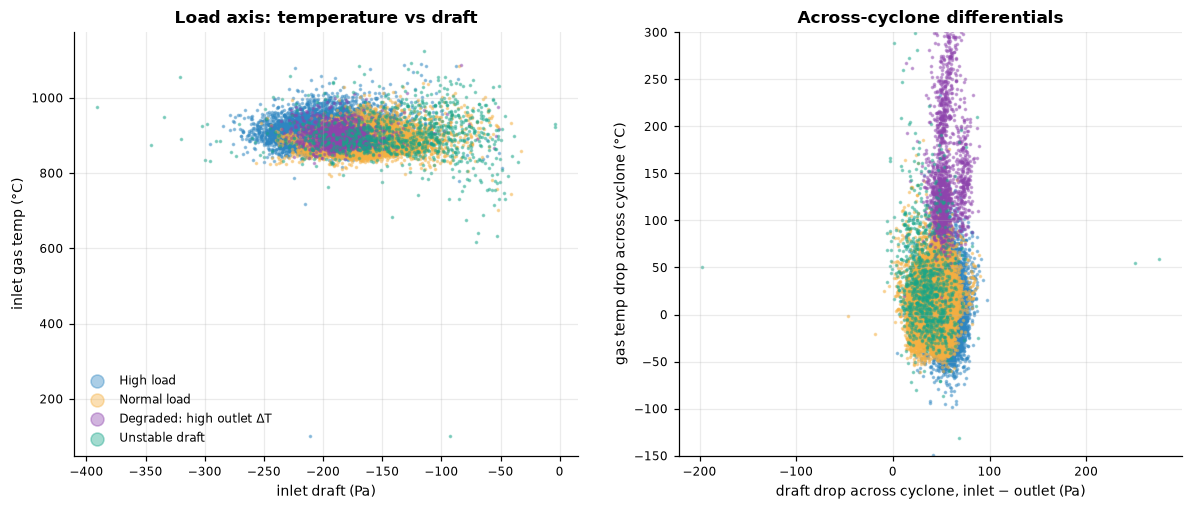

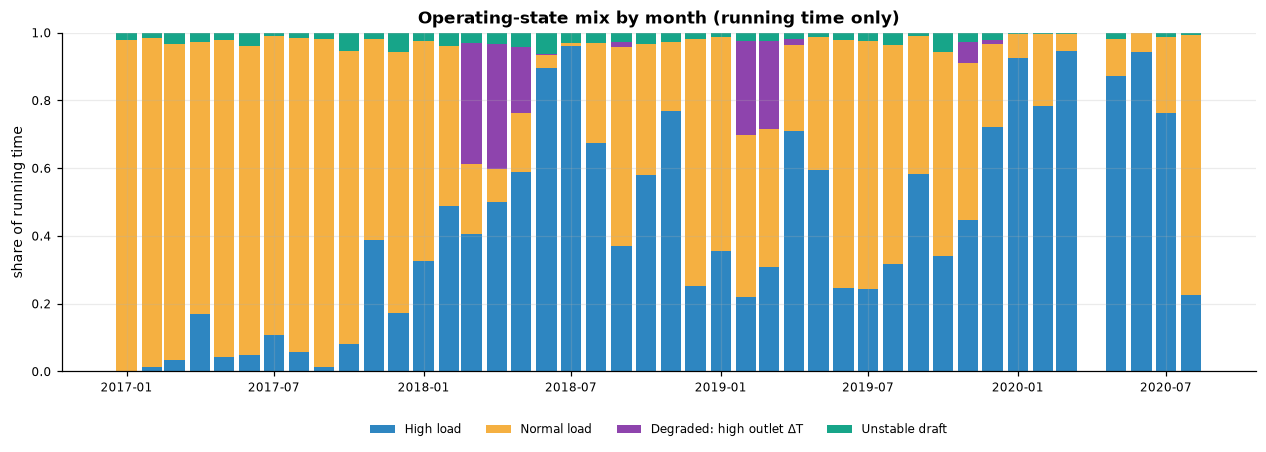

In [16]:
plots.state_scatter(Fa, labels, names, PLOTS / "3_states" / "05_states_scatter.png")
plots.state_share_monthly(labels, names, PLOTS / "3_states" / "05_state_mix_monthly.png");

The monthly mix shows something a single average would hide. The "Degraded" state is concentrated in two blocks, **Mar–May 2018 and Feb–Mar 2019**, and the plant shifts from mostly Normal load in 2017 (88% of running time) to mostly High load in 2020 (76–95% each month, Jan–Jul).

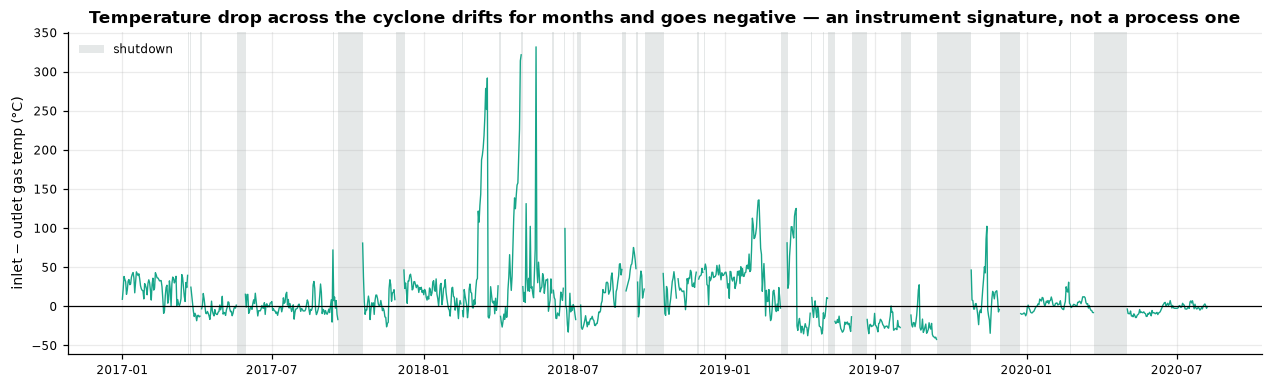

In [17]:
plots.temp_drop_drift(df, active, shut, PLOTS / "3_states" / "06_temp_drop_drift.png");

**This is instrument drift, not a process state.** The daily median of inlet − outlet gas temperature wanders from about +50 °C to about −30 °C over months. It changes in steps around stops (Apr 2019, Oct 2019), and for most of mid-2019 the outlet reads *hotter* than the inlet, which a cyclone with no heat source cannot do. The likely explanation is a thermocouple that drifts and is periodically re-seated or replaced during maintenance. Clustering faithfully isolated these periods as a "state". That is useful, but it also means an anomaly detector conditioned on states will treat them as normal (see section 4).

## 4. Contextual anomaly detection and root causes

**Detector 1: contextual Isolation Forest.** One IF per state, each fitted on that state's own feature distribution, so a reading is judged against what is normal *for that state*. Points above the pooled 99.5th percentile of the score are flagged and grouped into events (15-min gap tolerance; single-sample blips dropped unless extreme). For attribution, robust z-scores (median/MAD within the state) name the tags that moved and their direction.

**Detector 2: fan-trip rule.** Fan-off time is excluded from the running data the Isolation Forests are fitted on, so the IF never sees a fan trip. That avoids the blind spot of an earlier version, where trips were common enough to form their own cluster and were then scored as *normal for their state*. Every fan trip from the fan-off layer (section 2) is reported as an incident, with attribution measured against the state the line was in just before the fan stopped:
- `transient_fan_trip`: the fan was back within 60 min;
- `fan_trip_extended`: the fan stayed off 60 min or longer, and the line cooled further before recovering.

Coast-downs into a shutdown and start-up idle are part of a stop, not incidents, so they are not in this list.

In [18]:
scores = an.score(Fa, labels)
anoms = an.build_events(scores, feats, labels, fan, shut, names)
anoms.to_csv(OUT / "anomalous_periods.csv", index=False)
print(anoms["detector"].value_counts().to_string())
an.rate_by_state(scores, anoms, names)

detector
isolation_forest      254
transient_fan_trip     91
fan_trip_extended      66


,state,running_h,flagged_pct,if_events,if_events_per_1000h
state,,,,,
0,High load,10623.0,0.36,92,8.7
1,Normal load,12025.0,0.60,148,12.3
2,Degraded: high outlet ΔT,998.0,0.97,11,11.0
3,Unstable draft,584.0,0.33,3,5.1


duration_min                                               
                          count   mean    std   min   25%    50%    75%    max
detector                                                                      
fan_trip_extended          66.0  181.0  124.0  60.0  76.0  132.0  254.0  575.0
isolation_forest          254.0   25.0   33.0   5.0  10.0   15.0   25.0  335.0
transient_fan_trip         91.0   29.0   14.0  10.0  18.0   25.0   40.0   55.0

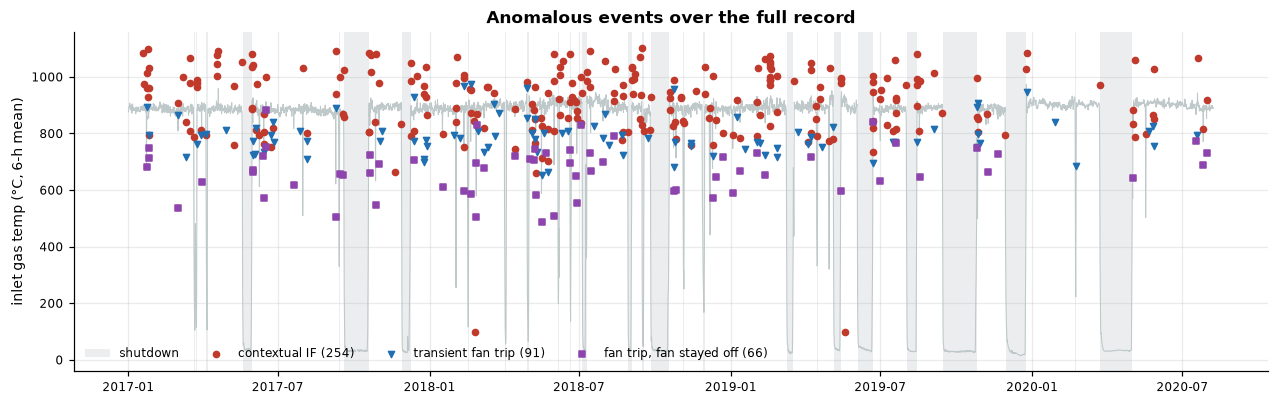

In [19]:
plots.anomaly_timeline(df, anoms, shut, PLOTS / "4_anomalies" / "07_anomaly_timeline.png")
anoms.groupby("detector")[["duration_min"]].describe().round(0)

In [20]:
iso = anoms[anoms["detector"] == "isolation_forest"]
trips = anoms[anoms["detector"] != "isolation_forest"]
print("IF events - primary variable:"); print(iso["primary_variable"].value_counts().to_string())
print("\nfan trips per year:"); print(trips.groupby([trips["start"].dt.year, "detector"]).size().unstack(fill_value=0))

IF events - primary variable:
primary_variable
inlet_draft      90
inlet_temp       70
outlet_draft     60
material_temp    11
temp_drop         9
draft_dp          5
cone_draft        5
outlet_temp       4

fan trips per year:
detector  fan_trip_extended  transient_fan_trip
start                                          
2017                     20                  28
2018                     29                  34
2019                     13                  23
2020                      4                   6


### Root-cause hypotheses for selected events

Five events, each a different kind. Each hypothesis rests on (a) the order in which tags moved, (b) the physical link between them, and (c) the state before and after. These are hypotheses: the data is 5-minute averages, and confirming them needs operator logs, fan current and damper positions.

event_id                                                                         61
start                                                           2017-06-14 11:35:00
end                                                             2017-06-14 11:55:00
duration_min                                                                     20
detector                                                         transient_fan_trip
state_id                                                                          1
state                                                     fan off (was Normal load)
peak_time                                                       2017-06-14 11:35:00
top_variables               inlet_draft +8.8σ; inlet_temp -7.0σ; outlet_draft +6.7σ
minutes_since_restart                                                        7790.0
minutes_to_next_shutdown                                                    67445.0


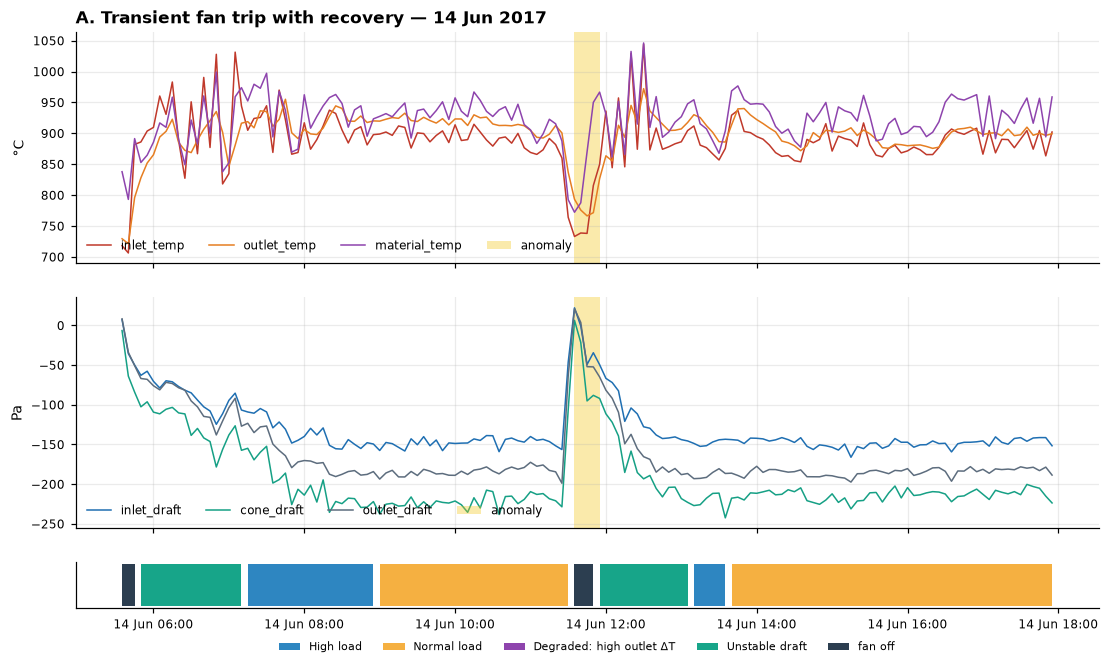

In [21]:
def show(start, title, pad="6h", table=None, detector=None):
    """Plot the event (from anomalous_periods, or another table such as fan_off_periods) starting closest to `start`."""
    t = anoms if table is None else table
    if detector is not None:
        t = t[t["detector"] == detector]
    near = (t["start"] - pd.Timestamp(start)).abs()  # within an hour, so a one-sample shift in a rule doesn't break the case
    assert near.min() <= pd.Timedelta("1h"), f"no event near {start}"
    r = t.loc[near.idxmin()]
    print(r.drop(labels=["peak_score", "primary_variable"], errors="ignore").to_string())
    fname = f"08_rca_{pd.Timestamp(start):%Y%m%d_%H%M}.png"
    plots.anomaly_context(df, labels, names, r, title, pad=pad, path=PLOTS / "4_anomalies" / fname, shutdowns=shut, fan_off=fan_off,
                          span_label="anomaly" if table is None else f"{r['kind'].replace('_', ' ')} (fan off)")
    plt.show()

show("2017-06-14 11:30", "A. Transient fan trip with recovery — 14 Jun 2017", detector="transient_fan_trip")

**A. Transient fan trip (14 Jun 2017, 11:35, fan off 20 min).**
*Evidence:* within one 5-min sample, all three drafts go from about −150/−220 Pa to **+20 Pa**. In the same sample, inlet gas falls ~130 °C (860 → 730 °C) and outlet and material temperatures follow. Draft then rebuilds over ~20 min, and temperatures recover to normal within an hour. The sequence is Normal load → fan off (11:35–11:55) → Unstable draft → High load → Normal load by 13:40.
*Hypothesis:* a momentary **ID fan trip** (or damper slam) that the fan control restarted. Losing draft first and temperature second is the signature of reduced gas flow: less hot gas is pulled through, so the temperatures sag. A blockage would instead make the drafts *diverge* (inlet more negative, outlet less), which doesn't happen here.
*This is the most common incident in the record.* There were 91 transient trips (fan back within an hour), roughly one every 11 days of running.

event_id                                                                        116
start                                                           2017-12-27 17:45:00
end                                                             2017-12-27 18:15:00
duration_min                                                                     30
detector                                                         transient_fan_trip
state_id                                                                          1
state                                                     fan off (was Normal load)
peak_time                                                       2017-12-27 18:00:00
top_variables               inlet_draft +9.3σ; outlet_draft +7.0σ; cone_draft +6.1σ
minutes_since_restart                                                       27240.0
minutes_to_next_shutdown                                                    51910.0


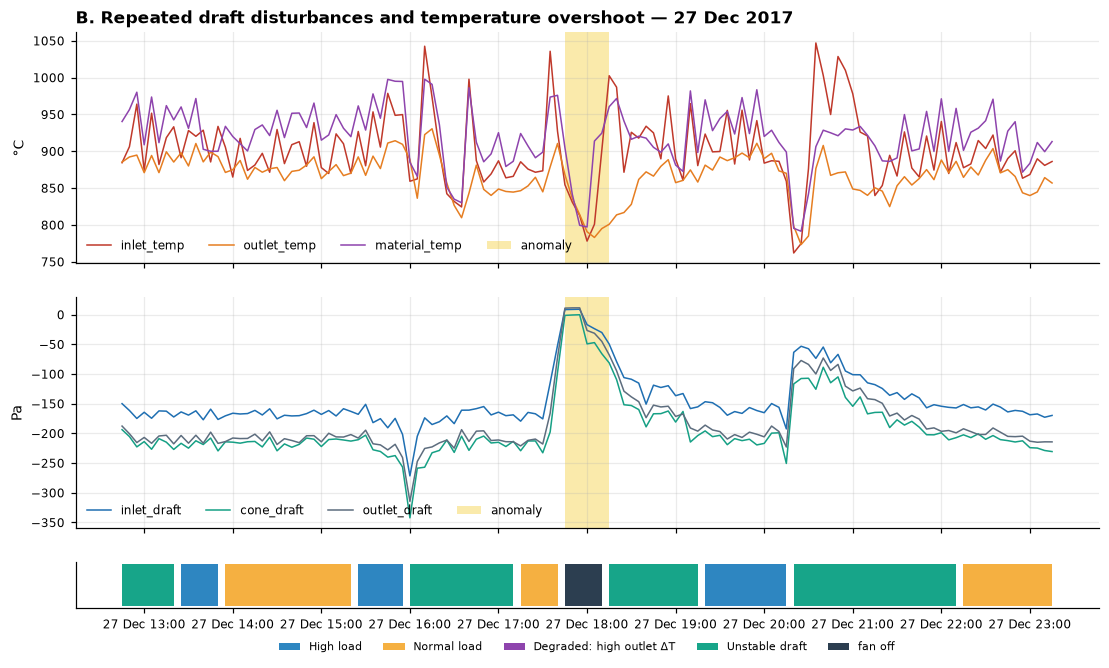

In [22]:
show("2017-12-27 17:45", "B. Repeated draft disturbances and temperature overshoot — 27 Dec 2017", pad="5h")

**B. Chain of draft disturbances (27 Dec 2017).**
*Evidence:* within about six hours there are three draft events. At ~16:00 there is a brief surge *stronger* than normal (−340 Pa). At 17:45 there is a full collapse to ~0 Pa for 30 min, which is the transient trip this case is anchored on. At 20:20 a partial loss to about −60 to −90 Pa follows. An earlier version flagged that partial loss as an IF anomaly. Now it is classified as an *Unstable draft* episode (20:20–22:15), and judged against other unstable-draft periods, where swings like this are normal. That is the contextual detector working as designed. The episode is still visible in `state_episodes.csv`. After each recovery, inlet gas **overshoots** to 1,000–1,050 °C, well above the ~900 °C norm.
*Hypothesis:* an **unstable draft control loop**, such as a sticking damper or a fan speed controller hunting, rather than a single fault. The overshoot after each recovery fits a temperature/fuel controller that kept firing while the gas flow was low, then over-delivered once flow returned. Repeated draft events within hours are worth an operator alert of their own, because the cumulative thermal swings stress refractory and the cyclone shell.

event_id                                                                             77
start                                                               2017-09-09 04:55:00
end                                                                 2017-09-09 13:05:00
duration_min                                                                        490
detector                                                              fan_trip_extended
state_id                                                                              1
state                                                         fan off (was Normal load)
peak_time                                                           2017-09-09 11:55:00
top_variables               inlet_temp -13.5σ; material_temp -11.7σ; inlet_draft +10.2σ
minutes_since_restart                                                           57045.0
minutes_to_next_shutdown                                                         5370.0


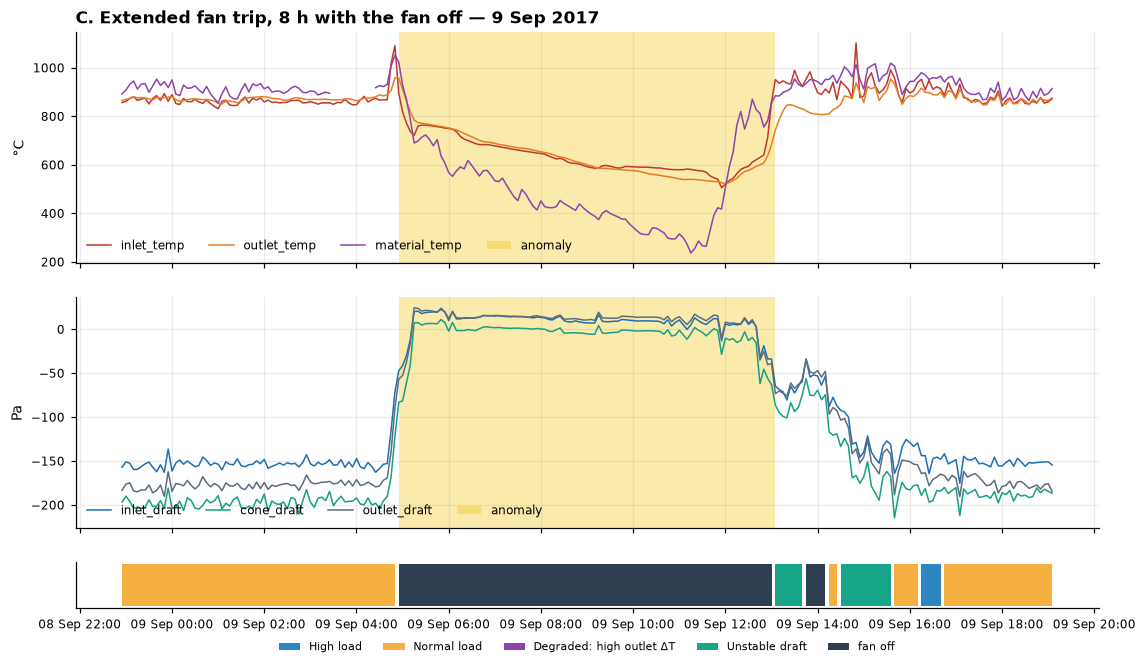

In [23]:
show("2017-09-09 04:50", "C. Extended fan trip, 8 h with the fan off — 9 Sep 2017", pad="6h", detector="fan_trip_extended")

**C. Extended fan trip (9 Sep 2017, 04:55, fan off 8 h).**
*Evidence:* about an hour earlier, material temperature drops to exactly 0.0 for ~55 min (a dropout, now removed by cleaning). At 04:45 inlet gas **spikes to 1,090 °C** (+9.8σ), and in the same samples the drafts start collapsing. By 05:15 they sit at about +20 Pa and stay there until 13:05 (490 min, the longest fan trip in the record) while the line coasts down to ~580 °C. That is still above the 477 °C threshold, so it never counts as a shutdown. The fan comes back at 13:05, trips once more for 30 min at 13:45, and the line is in Normal load from 15:40.
*Hypothesis:* an **ID fan trip that was not restarted for several hours** (a warm hold). The inlet spike is what you would expect when flow stops suddenly: the thermocouple sits in stagnant hot gas near the burner instead of a moving stream. The earlier material temperature dropout may be a coincidence, but a shared electrical or instrument-power fault is worth checking, since two instruments misbehaved within the same hour. The next real shutdown (12 Sep, 21:00) also starts with the draft collapsing before temperatures fall. That turns out to be how every stop in the record begins (section 6).

period_id                                   118
start                       2018-06-21 15:30:00
end                         2018-06-21 18:00:00
duration_min                                150
kind                               startup_idle
inlet_temp_before_c                       554.1
inlet_temp_min_c                          580.1
dip_c                                      26.0
minutes_since_restart                       0.0
minutes_to_next_shutdown                19150.0


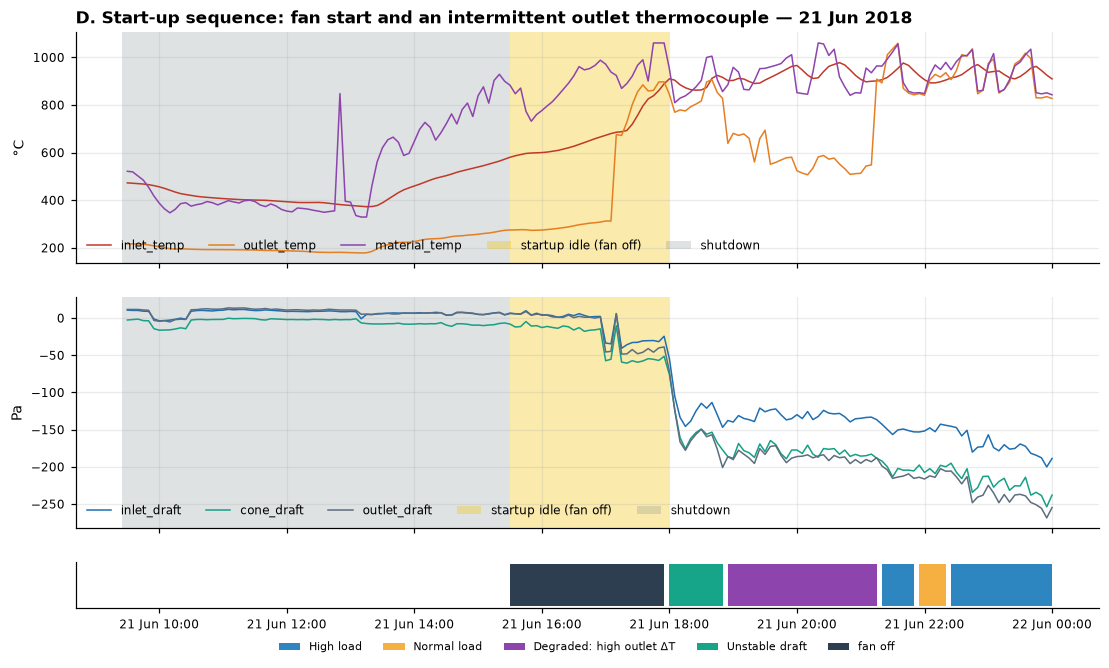

In [24]:
show("2018-06-21 15:30", "D. Start-up sequence: fan start and an intermittent outlet thermocouple — 21 Jun 2018", pad="6h", table=fan)

**D. Start-up (21 Jun 2018): a former false positive, now handled by design.**
*Evidence:* the line restarts at 15:30 with the fan off. Inlet gas climbs while outlet gas lags at ~300 °C. The fan comes up between 17:15 (drafts step to about −50 Pa) and 18:00 (full draft), and outlet gas jumps ~370 °C in one sample as hot gas reaches it. An earlier version of this analysis flagged the fan start as an anomaly, because start-ups are rare in the training data. Now the whole 15:30–18:00 period is a *start-up idle* fan-off period, which is excluded from running, so no alarm is raised. From 18:55 to 21:20, outlet gas drops ~300–400 °C in a **single step** (906 → ~550 °C) and comes back in another single step (→ 1,011 °C), while inlet, material and drafts stay steady. The states label exactly this stretch *Degraded: high outlet ΔT*.
*Hypothesis:* the start-up is **normal start-up practice** (burner first, fan second). The later step changes are an **intermittent outlet thermocouple** (a loose junction or connector). Real gas temperature cannot fall and recover 300 °C instantly while every other tag is flat. This is the same instrument as the drift in section 3.
*Takeaway:* treating start-up idle as idle removes this class of false alarm. The first fan-on hours after a restart remain the most anomaly-prone running time (section 6).

time
2019-01-20     51.0
2019-01-27     44.0
2019-02-03     60.0
2019-02-10    104.0
2019-02-17     66.0
2019-02-24     13.0
2019-03-03      5.0
2019-03-10      6.0
2019-03-17     81.0
2019-03-24     79.0
2019-03-31     66.0
2019-04-07    -27.0
2019-04-14    -26.0
2019-04-21     -2.0
Freq: W-SUN


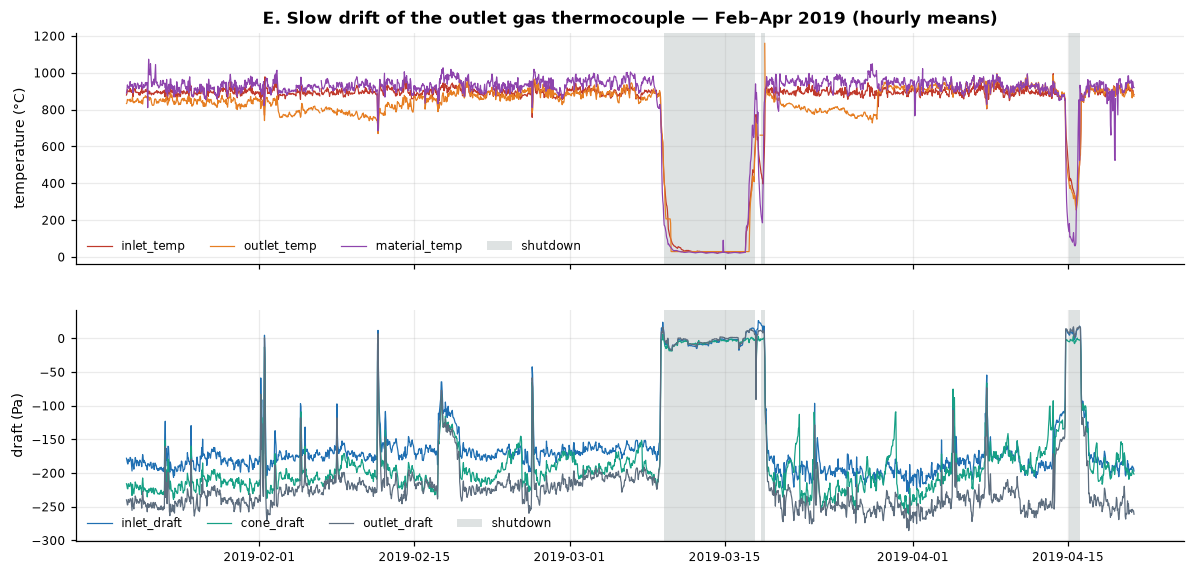

In [25]:
fig = plots.temps_and_drafts(df, "2019-01-20", "2019-04-20 23:55",
    "E. Slow drift of the outlet gas thermocouple — Feb–Apr 2019 (hourly means)",
    shutdowns=shut, resample="1h", path=PLOTS / "4_anomalies" / "08_rca_drift_2019.png")
d = (df["Cyclone_Inlet_Gas_Temp"] - df["Cyclone_Gas_Outlet_Temp"]).where(active)
print(d["2019-01-20":"2019-04-20"].resample("W").median().round(0).to_string())

**E. Slow drift (Feb–Apr 2019): an anomaly no point-detector will catch.**
*Evidence:* twice in this window, outlet gas sags slowly by 100–150 °C while inlet gas holds at ~900 °C: early to mid February, and again 20–28 Mar right after the March stop. Each sag ends in a **single step** back up. Inlet temperature, material temperature and the drafts show nothing matching. After the short stop on 7 Apr 2019 the gap flips to about −25 °C, with the outlet reading *hotter* than the inlet, and stays negative until Sep 2019.
*Hypothesis:* **outlet thermocouple degradation** (drift or fouling of the sheath), with the step changes marking interventions. A real loss of heat across the cyclone would also move material temperature or the pressure drop, and neither moves.
*Why it matters for the design:* a drift lasting weeks becomes the "normal" of its own cluster ("Degraded: high outlet ΔT"), so a contextual detector stops flagging it. Slow drift needs its own monitor: a daily check of inlet − outlet against a long baseline.

## 5. One-hour forecast of inlet gas temperature

- **Split:** train 2017-01 → 2019-12; test 2020-01 → 2020-08. This is chronological, with no shuffling, and the last hour of training targets is dropped so no target crosses into the test period.
- **Origins:** one per hour across the test period, each forecasting t+5 … t+60 min from data up to t.
- **Models:**
  - **persistence** (the baseline);
  - **ARIMA(2,1,2)**, fitted once on the last 4 weeks of training and re-filtered on the trailing 24 h at each origin. This is how it would run online, and it avoids 5,000 refits;
  - **gradient boosting** (sklearn `HistGradientBoostingRegressor`), direct strategy with one model per horizon. Features are lags, rolling stats, the other five tags and their 30-min changes, and time of day.
- **Regimes:** every origin is tagged by what happens within ±1 h. An average over the whole test set mostly reflects how much of it happens to be shut down.

In [26]:
fc, gbm_models = fcm.run(df, T_OFF)
fc.round(2).to_csv(OUT / "forecasts.csv", index=False)
m = fcm.metrics(fc)
m.to_csv(SUPPORT / "forecast_metrics.csv", index=False)
print((fc.groupby("regime")["origin"].nunique()).to_string())
m.pivot(index="subset", columns="model", values=["rmse", "mae"]).round(1)

regime
disturbed          239
shut_down          954
steady_running    4057
transition          12


rmse                     mae                  
model          arima   gbm persistence arima   gbm persistence
subset                                                        
all             16.8  15.1        19.4   9.8   9.5        11.8
disturbed       52.2  41.7        55.4  35.3  27.9        38.7
shut_down        6.2   5.6         5.0   1.3   2.5         0.9
steady_running  13.8  13.6        17.3  10.2  10.0        12.7
transition      37.4  17.2        26.7  31.7  13.1        20.8

,persistence_rmse,persistence_mae,arima_rmse,arima_mae,gbm_rmse,gbm_mae
horizon,,,,,,
1,17.05,12.48,13.24,9.83,12.94,9.55
6,17.23,12.84,13.94,10.40,13.71,10.18
12,17.59,13.08,14.19,10.51,14.10,10.42


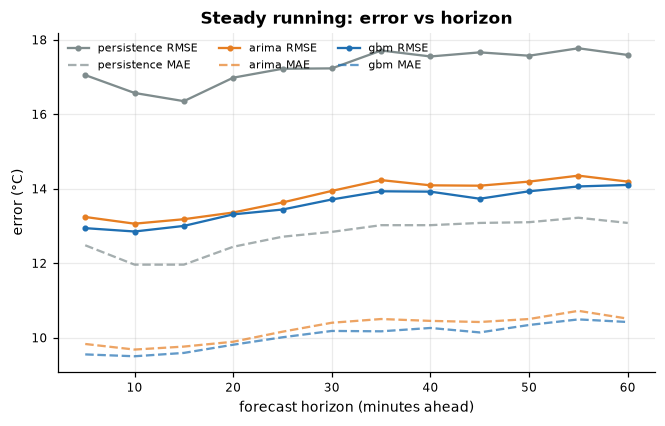

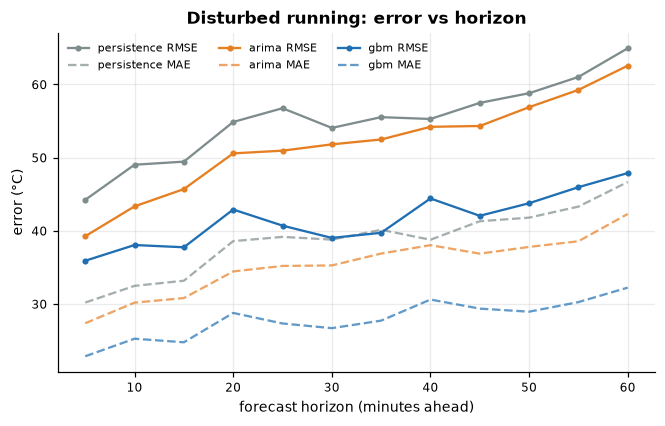

In [27]:
by_h_steady = fcm.metrics_by_horizon(fc, "steady_running")
by_h_dist = fcm.metrics_by_horizon(fc, "disturbed")
plots.forecast_horizon(by_h_steady, "Steady running: error vs horizon", PLOTS / "5_forecast" / "09_fc_horizon_steady.png")
plots.forecast_horizon(by_h_dist, "Disturbed running: error vs horizon", PLOTS / "5_forecast" / "09_fc_horizon_disturbed.png")
by_h_steady.iloc[[0, 5, 11]]

In [28]:
# where does the error come from? share of total squared error by regime
se = fc.assign(se_gbm=(fc["pred_gbm"] - fc["y_true"]) ** 2,
               se_persistence=(fc["pred_persistence"] - fc["y_true"]) ** 2)
share = se.groupby("regime")[["se_gbm", "se_persistence"]].sum()
(100 * share / share.sum()).round(1).assign(share_of_origins_pct=(100 * fc.groupby("regime").size() / len(fc)).round(1))

,se_gbm,se_persistence,share_of_origins_pct
regime,,,
disturbed,34.7,37.1,4.5
shut_down,2.5,1.2,18.1
steady_running,62.6,61.3,77.1
transition,0.3,0.4,0.2


In [29]:
# how much of the 5-min movement is noise? white noise around a level gives -0.5
y_run = df["Cyclone_Inlet_Gas_Temp"].where(~off)
dy = y_run.diff()
pd.Series({yr: dy[str(yr)].autocorr(1) for yr in range(2017, 2021)}, name="lag-1 autocorr of 5-min changes").round(2)

2017   -0.47
2018   -0.43
2019   -0.37
2020   -0.47
Name: lag-1 autocorr of 5-min changes, dtype: float64

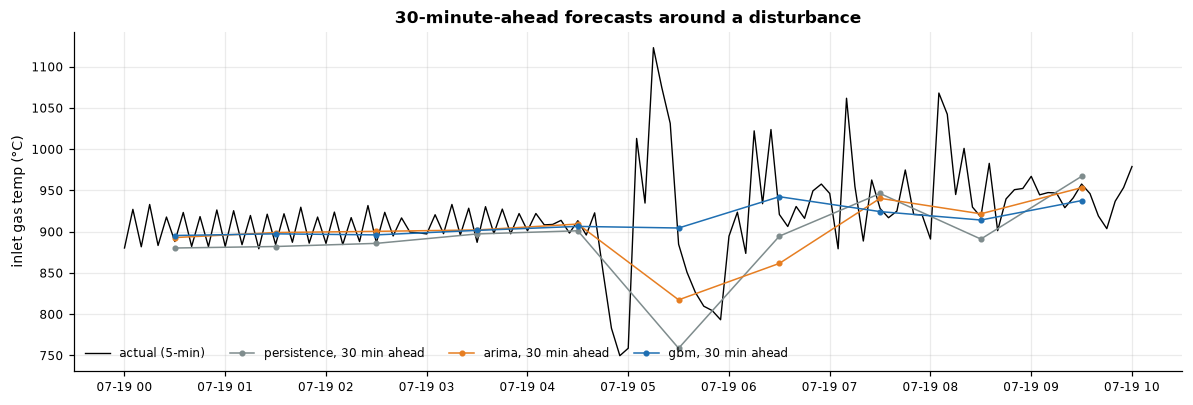

In [30]:
worst = fc[fc["regime"] == "disturbed"].groupby("origin")["y_true"].agg(lambda s: s.max() - s.min()).idxmax()
plots.forecast_example(df, fc, worst - pd.Timedelta("5h"), worst + pd.Timedelta("5h"), horizon=6,
                       path=PLOTS / "5_forecast" / "09_fc_example.png");

**Reading the results**

- **Steady running (about 77% of origins):** both models beat persistence by about 20% RMSE (≈ 13.6–13.8 vs 17.3 °C). ARIMA and gradient boosting are tied, so linear dynamics are enough when nothing is happening. Error grows only slowly with horizon, and the reason is in the data. Consecutive 5-minute changes have a lag-1 autocorrelation of about −0.43 in every year; pure white noise around a level would give −0.5. So most 5-minute movement is measurement noise around a slowly moving level. Persistence copies that noise into every forecast, while the models predict the level.
- **Disturbed running (4.5% of origins, but about 35% of all squared error):** errors triple for every model. Gradient boosting is clearly best here (≈ 42 vs 52 ARIMA vs 55 persistence RMSE), because the draft features carry the upset before temperature fully reacts. This is the only regime where the non-linear model earns its complexity.
- **Transitions:** there are only 12 origins in the test period, too few to rank models with confidence. ARIMA is worse than persistence here, though, because it extrapolates a trend straight through a regime change.
- **Shut down:** persistence is best, which is trivial, since the temperature is flat near ambient. Gradient boosting's small bias here is the cost of one model covering every regime.

**Practical challenges.** The process is non-stationary: the load mix shifts year to year (section 3), there is the thermocouple drift, and there is the long 2020 lockdown stop. Shutdowns are effectively unforecastable from temperature alone; the first sign is usually the draft. The test period also contains few transitions. In production I would (1) gate by regime, using persistence or a cooling curve when off, (2) retrain monthly on a rolling window, and (3) add fan current and damper position, which would give the model the upstream cause rather than its symptoms.

## 6. Insights and recommendations

The numbers below are computed from the outputs above.

In [31]:
trip_t = trips[trips["detector"] == "transient_fan_trip"]
ext = trips[trips["detector"] == "fan_trip_extended"]
running_h = len(Fa) * 5 / 60
def stops_preceded(ev, within):
    """Distinct shutdowns that have an event ending at most `within` before they start."""
    ends = ev["end"].to_numpy()
    return int(sum(((ends <= s.to_datetime64()) & (ends >= (s - within).to_datetime64())).any() for s in shut["start"]))
coast = fan[fan["kind"] == "coast_down"]
rmse = m.set_index(["subset", "model"])["rmse"]
dips = [df.loc[r.start:r.end, "Cyclone_Inlet_Gas_Temp"].min()
        - df.loc[r.start - pd.Timedelta("30min"):r.start - pd.Timedelta("5min"), "Cyclone_Inlet_Gas_Temp"].median()
        for r in trip_t.itertuples()]
# running hours that fall within 2 h after a restart
post_h = sum(((labels.index >= e) & (labels.index < e + pd.Timedelta("2h"))).sum() for e in shut["end"]) * 5 / 60
n_post = int(iso["minutes_since_restart"].le(120).sum())
facts = {
    "downtime, % of record": f"{100 * shut['duration_h'].sum() / (len(df) * 5 / 60):.1f}",
    "shutdowns": len(shut),
    "transient fan trips (recovered)": len(trip_t),
    "running days per transient trip": f"{running_h / 24 / len(trip_t):.1f}",
    "median inlet-temp dip during a transient trip, °C": f"{-np.nanmedian(dips):.0f}",
    "extended fan trips (fan off >= 60 min)": len(ext),
    "shutdowns that begin with the fan stopping (fan-off coast-down <= 3 h before)": f"{stops_preceded(coast, pd.Timedelta('3h'))} of {len(shut)}",
    "shutdowns preceded (<= 12 h) by an extended fan trip": f"{stops_preceded(ext, pd.Timedelta('12h'))} of {len(shut)}",
    "IF events in the 2 h after a restart": f"{n_post} of {len(iso)}",
    "IF events per 1000 running h: first 2 h after restart / elsewhere": f"{1000 * n_post / post_h:.0f} / {1000 * (len(iso) - n_post) / (running_h - post_h):.1f}",
    "IF events in the 3 h before a shutdown": f"{iso['minutes_to_next_shutdown'].le(180).sum()} of {len(iso)}",
    "running time in 'Degraded' (thermocouple) state, %": summary.loc[summary["state"].str.startswith("Degraded"), "share_of_running_pct"].iloc[0],
    "GBM vs persistence RMSE gain, steady / disturbed": " / ".join(
        f"{1 - rmse[(s, 'gbm')] / rmse[(s, 'persistence')]:.0%}" for s in ("steady_running", "disturbed")),
}
pd.Series(facts, name="value").to_frame()

,value
"downtime, % of record",19.9
shutdowns,39
transient fan trips (recovered),91
running days per transient trip,11.1
"median inlet-temp dip during a transient trip, °C",104
extended fan trips (fan off >= 60 min),66
shutdowns that begin with the fan stopping (fan-off coast-down <= 3 h before),39 of 39
shutdowns preceded (<= 12 h) by an extended fan trip,2 of 39
IF events in the 2 h after a restart,6 of 254
IF events per 1000 running h: first 2 h after restart / elsewhere,381 / 10.2


**1. ID-fan trips are the main operational problem, and every stop starts with the fan stopping.**
There were 91 *transient* trips, where draft collapsed to ~0 Pa and the fan was back within an hour (median 25 min, about one every 11 running days). Each cost a ~100 °C dip in inlet gas temperature. There were another 66 *extended* trips, with the fan off for an hour or more (median 2.2 h, ~200 °C dip). All 39 shutdowns begin the same way: the fan stops while the gas is still at ~890 °C, and the gas then takes a median ~7 h to cool past the shutdown threshold. The data can't tell a planned fan stop from a trip; a stop log can (see "How to validate" in the README).
→ *Alarm:* median draft above −60 Pa while inlet gas is above the shutdown threshold, for two consecutive samples. The draft collapses as fast as the 5-minute data can show (the same sample as the first temperature drop), and before a stop it comes hours before the shutdown is "visible" in temperature.
→ *Investigate:* fan motor current, vibration and interlock logs around the 157 trip timestamps (`anomalous_periods.csv`, detector `*_fan_trip*`; all fan-off periods are in `outputs/supporting/fan_off_periods.csv`). One root cause behind most of them would be the highest-value fix in this dataset.

**2. A meaningful part of what looks like process behaviour is instrument behaviour.**
The outlet gas thermocouple drifts for weeks at a time (Mar–May 2018 and Feb–Mar 2019). It also steps (case D), and for most of mid-2019 reads hotter than the inlet, which is impossible. This makes up the whole "Degraded" state, 4.1% of running time. The material temperature transmitter has nearly all the `Unit Down` codes, ~1,150 near-ambient dropouts while the gas is hot, and 2–4× the stale samples of any other tag.
→ *Monitor:* the daily median of inlet − outlet gas temperature against a long baseline (alert outside roughly −10 … +60 °C), and a stale-value check (identical reading for 20 min while running) on every tag.
→ *Maintenance:* check or calibrate the outlet thermocouple and the material temperature transmitter at each planned stop. Any model trained on these tags inherits their faults otherwise.

**3. Contextual anomalies cluster right after restarts, not before shutdowns.**
With the fan-off start-up excluded, only ~16 h in the whole record are fan-on running within 2 h of a restart. Those hours hold 6 of the 254 contextual-IF events: ~380 per 1,000 h, against ~10 for the rest of running. Six events is a small sample, but the gap is large. Only 1 of 254 events falls in the 3 h before a shutdown. Across the states, the IF event rate is highest in Normal load (12.3 per 1,000 h) and the Degraded thermocouple periods (11.0). It is lowest in Unstable draft (5.1), which is already the upset band, so little inside it looks unusual for it. The multivariate detector is good at spotting unusual operation, but it is not a shutdown predictor. The fan rule in (1) is.
→ Use wider limits, or a start-up–specific model, for the first ~2 h of fan-on running after a restart.

**4. Load has shifted upward, and stops are seasonal.**
2017 ran mostly in the Normal-load band (88% of running time); Jan–Jul 2020 ran 76–95% in the High-load band each month. Downtime is 20% of the record. Most of it comes from 13 outages of 4–42 days, including a September stop of 3–6 weeks each year 2017–2019 and the Mar–May 2020 lockdown. The other 26 stops are under 2.5 days.
→ Retrain the state, anomaly and forecast models on a rolling window (e.g. monthly). A model fitted on 2017 sees 2020's normal as unusual (temporal ARI 0.75 in section 3).